# Do our rankings agree with published ones? (men's D1)
References (saved in `ratings/reference/`): **NCAA RPI** (through Nov 3, 2026), **Shortlistr Team Strength**, and the **United Soccer Coaches** polls (top 25 only). Our ratings only use matches played up to the reference's date. Some schools cannot be matched by name and are excluded (listed as `unmatched`).

In [1]:
%matplotlib inline
import sys, json, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "ratings").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ratings import base
from ratings.data import load_matches
from ratings.tune import PARAMS_PATH, load_best
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from ratings.compare_rpi import compare as compare_reference, REFERENCES
from ratings.compare_polls import compare as compare_poll

## 1. 2026 snapshot: RPI and Shortlistr

In [2]:
matches_men = load_matches("male")
MODELS = ["elo_none", "elo_sqrt", "elo_xg", "glicko", "pi", "dixon_coles", "dixon_coles_xg", "ridge_gd_xg"]
rows, tables = [], {}
for ref in REFERENCES:
    for name in MODELS:
        table, summary = compare_reference(name, "2026-11-03", 2026, matches_men, ref=ref)
        rows.append(summary)
        tables[(ref, name)] = table
snapshot = pd.DataFrame(rows)
display(snapshot.pivot(index="model", columns="ref", values="spearman").round(3)
        .assign(mean=lambda d: d.mean(axis=1)).sort_values("mean", ascending=False))
display(snapshot.round(3))

ref,rpi,shortlistr,mean
model,,,
elo_sqrt,0.929,0.899,0.9140
glicko,0.943,0.882,0.9125
pi,0.917,0.904,0.9105
elo_xg,0.911,0.909,0.9100
elo_none,0.930,0.871,0.9005
dixon_coles_xg,0.902,0.862,0.8820
dixon_coles,0.903,0.837,0.8700
ridge_gd_xg,0.883,0.822,0.8525


,ref,model,ref_teams,matched,spearman,kendall,top10_overlap,top25_overlap,mean_abs_rank_diff
0,rpi,elo_none,213,203,0.930,0.773,7,19,30.635
1,rpi,elo_sqrt,213,203,0.929,0.770,6,19,28.010
2,rpi,elo_xg,213,203,0.911,0.742,5,18,31.764
3,rpi,glicko,213,203,0.943,0.799,7,19,22.936
4,rpi,pi,213,203,0.917,0.752,4,18,29.232
5,rpi,dixon_coles,213,203,0.903,0.737,4,17,21.552
6,rpi,dixon_coles_xg,213,203,0.902,0.728,4,17,22.571
7,rpi,ridge_gd_xg,213,203,0.883,0.700,5,16,25.374
8,shortlistr,elo_none,199,198,0.871,0.684,6,16,36.934
9,shortlistr,elo_sqrt,199,198,0.899,0.723,7,16,32.030


### Biggest disagreements for one model

In [3]:
name = "elo_sqrt"
for ref in REFERENCES:
    table = tables[(ref, name)].dropna(subset=["model_rank"]).copy()
    table["diff"] = table["model_rank"] - table["rank"]
    print(f"== {name} vs {ref}: model ranks the team better (-) / worse (+) than the reference ==")
    display(pd.concat([table.nsmallest(8, "diff"), table.nlargest(8, "diff")])[["school", "rank", "model_rank", "diff"]])
    print("unmatched:", tables[(ref, name)].loc[lambda d: d.team_id.isna(), "school"].tolist())

== elo_sqrt vs rpi: model ranks the team better (-) / worse (+) than the reference ==


,school,rank,model_rank,diff
170,San Jose St.,171,91.0,-80.0
155,Stetson,156,81.0,-75.0
160,Lindenwood,161,92.0,-69.0
130,Seattle U,131,83.0,-48.0
83,Dayton,84,39.0,-45.0
137,Bellarmine,138,94.0,-44.0
167,SIUE,168,124.0,-44.0
172,West Florida,173,130.0,-43.0
109,Butler,110,216.0,106.0
141,Saint Peter's,142,236.0,94.0


unmatched: ['Sacred Heart', 'Boston U.', 'ETSU', 'FGCU', 'LMU (CA)', 'UIW', 'Houston Christian', 'St. Thomas (MN)', "Saint Mary's (CA)", 'Western Ill.']
== elo_sqrt vs shortlistr: model ranks the team better (-) / worse (+) than the reference ==


,school,rank,model_rank,diff
171,Seattle,172,83.0,-89.0
110,Dayton,111,39.0,-72.0
126,Denver,127,59.0,-68.0
151,Coastal Carolina,152,93.0,-59.0
107,Duke,108,51.0,-57.0
127,St. John's,128,72.0,-56.0
96,North Florida,97,50.0,-47.0
156,American,157,111.0,-46.0
122,Saint Peter's,123,236.0,113.0
116,UMBC,117,228.0,111.0


unmatched: ['Sacred Heart']


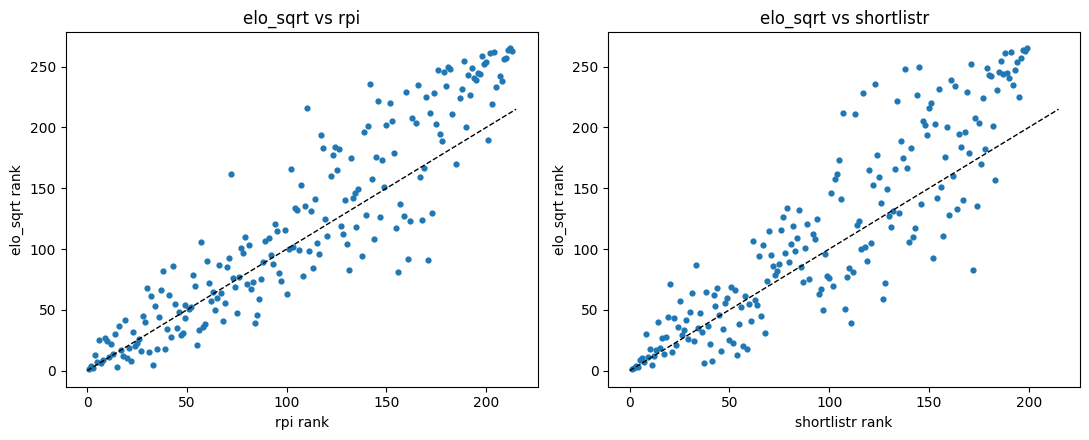

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ref in zip(axes, REFERENCES):
    table = tables[(ref, name)].dropna(subset=["model_rank"])
    ax.scatter(table["rank"], table["model_rank"], s=12)
    ax.plot([0, 215], [0, 215], "k--", lw=1)
    ax.set_xlabel(f"{ref} rank"); ax.set_ylabel(f"{name} rank"); ax.set_title(f"{name} vs {ref}")
plt.tight_layout(); plt.show()

## 2. Coaches poll, 2026 (top 25 only)

In [5]:
poll_rows = []
for name in ["elo_sqrt", "elo_xg", "glicko", "dixon_coles_xg"]:
    table, summary = compare_poll("male", name, matches_men)
    poll_rows.append(summary)
display(pd.DataFrame(poll_rows).round(3))

,model,gender,teams_matched,n_ranked_teams,spearman,kendall,poll_top10_in_model_top10,poll_top25_in_model_top25,poll_top25_in_model_top50,median_model_rank_of_poll
0,elo_sqrt,male,25,265,0.670,0.497,8,21,25,14.0
1,elo_xg,male,25,265,0.664,0.491,6,17,24,16.0
2,glicko,male,25,265,0.700,0.544,6,21,25,16.0
3,dixon_coles_xg,male,25,265,0.696,0.531,5,15,24,17.0


## 3. Many seasons (2021-2026)
`history.run()` walks each model through all matches once and records its team strengths on the date of every reference (so there is no look-ahead), then compares with Shortlistr (2023-26), the coaches' Week-11 poll (2021-26), the Final poll (2021-25) and the 2026 RPI. Polls cover 25 teams, so besides rank correlation we count how many poll teams also sit in the model's top 25 / top 50.

Set `RUN_HISTORY = True` to recompute and overwrite `history_results.csv` (takes a long time; needs the database).

In [6]:
RUN_HISTORY = False
if RUN_HISTORY:
    from ratings.history import run
    run()
hist = pd.read_csv(ROOT / "ratings" / "history_results.csv")
display(hist.pivot_table(index="model", columns=["ref", "year"], values="spearman").round(2))
display(hist.pivot_table(index="model", columns="ref", values="spearman").round(3)
        .assign(overall=lambda d: d.mean(axis=1)).sort_values("overall", ascending=False))

ref                rpi shortlistr                   usc_final                         usc_wk11                              
year              2026       2023  2024  2025  2026      2021  2022  2023  2024  2025     2021  2022  2023  2024  2025  2026
model                                                                                                                       
dixon_coles       0.92       0.86  0.87  0.89  0.87      0.73  0.29  0.22  0.32  0.25     0.66  0.14  0.43  0.77  0.31  0.57
dixon_coles_xg    0.92       0.88  0.90  0.90  0.89      0.79  0.23  0.23  0.21  0.32     0.65  0.21  0.38  0.67  0.18  0.70
elo_none          0.93       0.85  0.91  0.91  0.87      0.77  0.65  0.64  0.60  0.54     0.66  0.26  0.55  0.77  0.67  0.61
elo_sqrt          0.93       0.88  0.93  0.93  0.90      0.84  0.67  0.67  0.54  0.58     0.65  0.29  0.52  0.88  0.74  0.67
elo_wfe_autocorr  0.93       0.87  0.91  0.91  0.88      0.85  0.66  0.65  0.47  0.47     0.66  0.26  0.53  0.81  0.72  0.55
elo_xg            0.91       0.91  0.93  0.93  0.91      0.81  0.58  0.38  0.28  0.42     0.68  0.26  0.37  0.74  0.35  0.66
ensemble_mean     0.94       0.89  0.92  0.92  0.90      0.88  0.64  0.47  0.42  0.46     0.70  0.35  0.48  0.83  0.54  0.70
ensemble_ols      0.92       0.89  0.91  0.91  0.91      0.83  0.42  0.31  0.22  0.35     0.66  0.25  0.42  0.68  0.24  0.70
glicko            0.94       0.87  0.90  0.91  0.88      0.73  0.60  0.57  0.34  0.46     0.70  0.40  0.65  0.70  0.70  0.70
pi                0.92       0.88  0.93  0.93  0.90      0.81  0.62  0.41  0.34  0.55     0.54  0.23  0.46  0.66  0.47  0.70
ridge_gd          0.92       0.89  0.90  0.92  0.90      0.88  0.47  0.34  0.26  0.47     0.62  0.39  0.33  0.61  0.39  0.47
ridge_gd_xg       0.90       0.84  0.85  0.85  0.85      0.84  0.27  0.40  0.02  0.35     0.57  0.26  0.40  0.49  0.12  0.60

ref,rpi,shortlistr,usc_final,usc_wk11,overall
model,,,,,
elo_sqrt,0.929,0.909,0.660,0.623,0.78025
elo_none,0.930,0.884,0.640,0.585,0.75975
elo_wfe_autocorr,0.926,0.891,0.620,0.588,0.75625
ensemble_mean,0.935,0.909,0.574,0.601,0.75475
glicko,0.943,0.889,0.539,0.643,0.75350
pi,0.917,0.910,0.546,0.511,0.72100
elo_xg,0.911,0.920,0.495,0.511,0.70925
ridge_gd,0.924,0.903,0.483,0.470,0.69500
ensemble_ols,0.920,0.904,0.428,0.491,0.68575


### Do the polls' top-25 teams show up in our top 25 / top 50?

In [7]:
polls = hist[hist.ref.str.startswith("usc")]
print("in model top 25 (of 25)")
display(polls.pivot_table(index="model", columns="ref", values="ref_top25_in_model_top25").round(1))
print("in model top 50 (of 25)")
display(polls.pivot_table(index="model", columns="ref", values="ref_top25_in_model_top50").round(1))

in model top 25 (of 25)


ref,usc_final,usc_wk11
model,,
dixon_coles,18.2,17.7
dixon_coles_xg,18.2,17.5
elo_none,20.6,20.2
elo_sqrt,19.6,20.3
elo_wfe_autocorr,20.4,19.8
elo_xg,19.4,19.3
ensemble_mean,20.0,20.3
ensemble_ols,18.8,18.8
glicko,21.0,20.8


in model top 50 (of 25)


ref,usc_final,usc_wk11
model,,
dixon_coles,24.4,23.8
dixon_coles_xg,24.2,23.8
elo_none,24.8,24.8
elo_sqrt,24.4,24.8
elo_wfe_autocorr,24.4,24.5
elo_xg,24.2,24.5
ensemble_mean,25.0,24.8
ensemble_ols,24.6,24.3
glicko,24.8,25.0


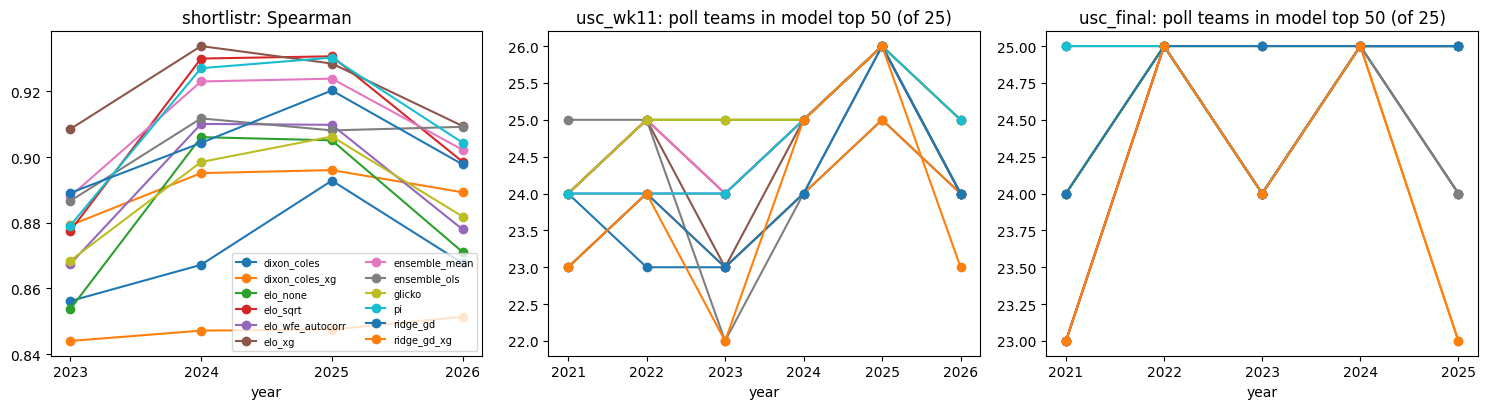

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, ref in zip(axes, ["shortlistr", "usc_wk11", "usc_final"]):
    value = "ref_top25_in_model_top50" if ref.startswith("usc") else "spearman"
    by_year = hist[hist.ref == ref].pivot_table(index="year", columns="model", values=value)
    by_year.plot(ax=ax, marker="o", legend=False)
    ax.set_title(f"{ref}: " + ("poll teams in model top 50 (of 25)" if ref.startswith("usc") else "Spearman"))
    ax.set_xticks(by_year.index)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()